# Terza Milestone Tesi
→ Tutti i risultati devono riportare Accuracy, Macro Averaged Precision, Macro Averaged Recall e Macro Averaged F-Measure.  
→ Tutti i risultati devono riportare il Delay (ossia quanti fotogrammi passano prima che io mi fermi e dia una risposta).  
→ Queste 5 metriche le vorrei vedere su tutte le euristiche, in bar chart (un bar chart per metrica, con 3 barre).  
→ Tutti i risultati devono riportare un intervallo di confidenza.  
  
Produrre i 15 risultati per un dataset che utilizza come training e validation set tutti i video di un solo individuo e come test tutti gli altri (divisione KOICV Keep One In Cross Validation).

Questo va fatto 7 volte, lasciando fuori a turno tutti gli individui, mostrando poi i risultati medi.


## 1 - Importazioni, installazioni e Google Drive

In [ ]:
!pip install ultralytics

import os
from pathlib import Path
import shutil
from natsort import natsorted
import yaml
import ultralytics
import numpy as np
import pandas
import json
import math
import matplotlib.pyplot as plt
import scipy
from google.colab import drive

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 10.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


## 2 - Configurazioni e parametri globali

In [ ]:
dataset_path = "/content/third-milestone/dataset-originale/"

os.makedirs("/content/third-milestone/", exist_ok=True)
os.makedirs("/content/third-milestone/LOOCV/", exist_ok=True)
os.makedirs("/content/third-milestone/LOOCV/configurations/", exist_ok=True)
os.makedirs("/content/third-milestone/LOOCV/configurations/fold1/", exist_ok=True)
os.makedirs("/content/third-milestone/LOOCV/configurations/fold2/", exist_ok=True)
os.makedirs("/content/third-milestone/LOOCV/configurations/fold3/", exist_ok=True)
os.makedirs("/content/third-milestone/LOOCV/configurations/fold4/", exist_ok=True)
os.makedirs("/content/third-milestone/LOOCV/configurations/fold5/", exist_ok=True)
os.makedirs("/content/third-milestone/LOOCV/configurations/fold6/", exist_ok=True)
os.makedirs("/content/third-milestone/LOOCV/configurations/fold7/", exist_ok=True)
os.makedirs("/content/third-milestone/LOOCV/models/", exist_ok=True)
os.makedirs("/content/third-milestone/LOOCV/models/fold1/", exist_ok=True)
os.makedirs("/content/third-milestone/LOOCV/models/fold2/", exist_ok=True)
os.makedirs("/content/third-milestone/LOOCV/models/fold3/", exist_ok=True)
os.makedirs("/content/third-milestone/LOOCV/models/fold4/", exist_ok=True)
os.makedirs("/content/third-milestone/LOOCV/models/fold5/", exist_ok=True)
os.makedirs("/content/third-milestone/LOOCV/models/fold6/", exist_ok=True)
os.makedirs("/content/third-milestone/LOOCV/models/fold7/", exist_ok=True)
os.makedirs("/content/third-milestone/LOOCV/results/", exist_ok=True)
os.makedirs("/content/third-milestone/LOOCV/results/fold1/", exist_ok=True)
os.makedirs("/content/third-milestone/LOOCV/results/fold2/", exist_ok=True)
os.makedirs("/content/third-milestone/LOOCV/results/fold3/", exist_ok=True)
os.makedirs("/content/third-milestone/LOOCV/results/fold4/", exist_ok=True)
os.makedirs("/content/third-milestone/LOOCV/results/fold5/", exist_ok=True)
os.makedirs("/content/third-milestone/LOOCV/results/fold6/", exist_ok=True)
os.makedirs("/content/third-milestone/LOOCV/results/fold7/", exist_ok=True)
os.makedirs("/content/third-milestone/LOOCV/final-results/", exist_ok=True)

drive.mount("/content/gdrive")

dataset_zip = Path("/content/gdrive/MyDrive/tesi-finale/videos-by-people.zip")
if not dataset_zip.is_file():
    dataset_zip = Path("/content/gdrive/MyDrive/tesi/videos-by-people.zip")
shutil.copy2(dataset_zip, "/content/third-milestone/videos-by-people.zip")
!unzip -q /content/third-milestone/videos-by-people.zip -d /content/third-milestone/
if os.path.exists("/content/third-milestone/videos-by-people.zip"):
    os.remove("/content/third-milestone/videos-by-people.zip")
os.rename("/content/third-milestone/videos-by-people/", "/content/third-milestone/dataset-originale/")

drive.flush_and_unmount()

number_of_participants = 7

## 3 - Analisi e indicizzazione del dataset

In [ ]:
original_dataset = Path(dataset_path)

all_participants = set()
for participant_path in original_dataset.iterdir():
  all_participants.add(participant_path.name)
are_there_exactly_seven_participants = len(all_participants) == 7

ogni_video_ha_imm_e_lbl = True
for participant_path in original_dataset.iterdir():
  for video_path in participant_path.iterdir():
    images_path = video_path / "images"
    labels_path = video_path / "labels"
    if not (images_path.is_dir() and labels_path.is_dir()):
      ogni_video_ha_imm_e_lbl = False

ogni_video_ha_una_classe = True
for participant_path in original_dataset.iterdir():
  for video_path in participant_path.iterdir():
    class_files = list(video_path.glob('*.class'))
    if not (len(class_files) == 1):
      ogni_video_ha_una_classe = False

classi_valide = True
for participant_path in original_dataset.iterdir():
  for video_path in participant_path.iterdir():
    class_files = list(video_path.glob('*.class'))
    for class_file in class_files:
      if class_file.stem not in {"driver", "passenger"}:
        classi_valide = False

esattamente_dieci_foto = True
for participant_path in original_dataset.iterdir():
  for video_path in participant_path.iterdir():
    images_path = video_path / "images"
    images_num = 0
    for image_path in images_path.iterdir():
      images_num += 1
    if images_num != 10:
      esattamente_dieci_foto = False

ogni_img_ha_ann = True
for participant_path in original_dataset.iterdir():
  for video_path in participant_path.iterdir():
    images_path = video_path / "images"
    labels_path = video_path / "labels"
    for image_path in images_path.iterdir():
      if image_path.is_file() and image_path.suffix.lower() == ".jpg":
        label_path = labels_path / f"{image_path.stem}.txt"
        if not label_path.is_file():
          ogni_img_ha_ann = False

id_compresi_0_6 = True
for participant_path in original_dataset.iterdir():
  for video_path in participant_path.iterdir():
    labels_path = video_path / "labels"
    for label_path in labels_path.iterdir():
      if label_path.is_file() and label_path.suffix.lower() == ".txt":
        with label_path.open('r', encoding='utf-8') as f:
          first_chars = [line[0] for line in f if line.strip()]
        for ch in first_chars:
          if not (0 <= int(ch) and int(ch) <= 6):
            id_compresi_0_6 = False

print(f"1 - Esistono esattamente sette partecipanti? -> {"Sì" if are_there_exactly_seven_participants else "No"}")
print(f"2 - Ogni video possiede le directory images e labels? -> {"Sì" if ogni_video_ha_imm_e_lbl else "No"}")
print(f"3 - Ogni video possiede un solo file .class? -> {"Sì" if ogni_video_ha_una_classe else "No"}")
print(f"4 - Il file .class identifica driver oppure passenger? -> {"Sì" if classi_valide else "No"}")
print(f"5 - Ogni video contiene i dieci fotogrammi previsti? -> {"Sì" if esattamente_dieci_foto else "No"}")
print(f"6 - Ogni immagine possiede la propria annotazione? -> {"Sì" if ogni_img_ha_ann else "No"}")
print(f"7 - Gli ID delle annotazioni sono compresi tra 0 e 6? -> {"Sì" if id_compresi_0_6 else "No"}")

1 - Esistono esattamente sette partecipanti? -> Sì
2 - Ogni video possiede le directory images e labels? -> Sì
3 - Ogni video possiede un solo file .class? -> Sì
4 - Il file .class identifica driver oppure passenger? -> Sì
5 - Ogni video contiene i dieci fotogrammi previsti? -> Sì
6 - Ogni immagine possiede la propria annotazione? -> Sì
7 - Gli ID delle annotazioni sono compresi tra 0 e 6? -> Sì


In [ ]:
videos_index = []

original_dataset = Path(dataset_path)
for elem in original_dataset.iterdir():
  if elem.is_dir():
    for elem2 in elem.iterdir():
      if elem2.is_dir():
        video_dictionary = {}
        frames_number = 0
        video_dictionary["Partecipante"] = elem.name
        video_dictionary["Nome video"] = elem2.name
        video_dictionary["Directory del video"] = str(elem2.resolve())
        for elem3 in elem2.iterdir():
          if elem3.is_dir():
            if elem3.name == "images":
              video_dictionary["Directory immagini"] = str(elem3.resolve())
              for elem4 in elem3.iterdir():
                if elem4.is_file():
                  if elem4.suffix.lower() == ".jpg":
                    frames_number += 1
            elif elem3.name == "labels":
              video_dictionary["Directory annotazioni"] = str(elem3.resolve())
          elif elem3.is_file():
            if elem3.suffix.lower() == ".class":
              video_dictionary["Classe reale"] = elem3.stem
        video_dictionary["Numero fotogrammi"] = frames_number
        videos_index.append(video_dictionary)

In [ ]:
videos_dataframe = pandas.DataFrame(videos_index)
videos_dataframe

,Partecipante,Nome video,Directory del video,Classe reale,Directory immagini,Directory annotazioni,Numero fotogrammi
0,set6,set6-driver-day-nobj-differentcolor,/content/third-milestone/dataset-originale/set...,driver,/content/third-milestone/dataset-originale/set...,/content/third-milestone/dataset-originale/set...,10
1,set6,set6-backrightpassenger-day-nobj-similarcolor,/content/third-milestone/dataset-originale/set...,passenger,/content/third-milestone/dataset-originale/set...,/content/third-milestone/dataset-originale/set...,10
2,set6,set6-backrightpassenger-day-obj-differentcolor,/content/third-milestone/dataset-originale/set...,passenger,/content/third-milestone/dataset-originale/set...,/content/third-milestone/dataset-originale/set...,10
3,set6,set6-backleftpassenger-day-obj-similarcolor,/content/third-milestone/dataset-originale/set...,passenger,/content/third-milestone/dataset-originale/set...,/content/third-milestone/dataset-originale/set...,10
4,set6,set6-frontpassenger-day-nobj-differentcolor,/content/third-milestone/dataset-originale/set...,passenger,/content/third-milestone/dataset-originale/set...,/content/third-milestone/dataset-originale/set...,10
...,...,...,...,...,...,...,...
187,set2,set2-backleftpassenger-night-nobj-similarcolor,/content/third-milestone/dataset-originale/set...,passenger,/content/third-milestone/dataset-originale/set...,/content/third-milestone/dataset-originale/set...,10
188,set2,set2-frontpassenger-day-nobj-similarcolor,/content/third-milestone/dataset-originale/set...,passenger,/content/third-milestone/dataset-originale/set...,/content/third-milestone/dataset-originale/set...,10
189,set2,set2-frontpassenger-night-nobj-differentcolor,/content/third-milestone/dataset-originale/set...,passenger,/content/third-milestone/dataset-originale/set...,/content/third-milestone/dataset-originale/set...,10
190,set2,set2-backrightpassenger-day-obj-similarcolor,/content/third-milestone/dataset-originale/set...,passenger,/content/third-milestone/dataset-originale/set...,/content/third-milestone/dataset-originale/set...,10


In [ ]:
sets_index = [
    {"Partecipante": "set1", "Video": 0, "Fotogrammi": 0},
    {"Partecipante": "set2", "Video": 0, "Fotogrammi": 0},
    {"Partecipante": "set3", "Video": 0, "Fotogrammi": 0},
    {"Partecipante": "set4", "Video": 0, "Fotogrammi": 0},
    {"Partecipante": "set5", "Video": 0, "Fotogrammi": 0},
    {"Partecipante": "set6", "Video": 0, "Fotogrammi": 0},
    {"Partecipante": "set7", "Video": 0, "Fotogrammi": 0},
]

for video in videos_index:
  if video["Partecipante"] == "set1":
    sets_index[0]["Video"] += 1
    sets_index[0]["Fotogrammi"] += 10
  elif video["Partecipante"] == "set2":
    sets_index[1]["Video"] += 1
    sets_index[1]["Fotogrammi"] += 10
  elif video["Partecipante"] == "set3":
    sets_index[2]["Video"] += 1
    sets_index[2]["Fotogrammi"] += 10
  elif video["Partecipante"] == "set4":
    sets_index[3]["Video"] += 1
    sets_index[3]["Fotogrammi"] += 10
  elif video["Partecipante"] == "set5":
    sets_index[4]["Video"] += 1
    sets_index[4]["Fotogrammi"] += 10
  elif video["Partecipante"] == "set6":
    sets_index[5]["Video"] += 1
    sets_index[5]["Fotogrammi"] += 10
  elif video["Partecipante"] == "set7":
    sets_index[6]["Video"] += 1
    sets_index[6]["Fotogrammi"] += 10

sets_dataframe = pandas.DataFrame(sets_index)
sets_dataframe

,Partecipante,Video,Fotogrammi
0,set1,32,320
1,set2,32,320
2,set3,16,160
3,set4,32,320
4,set5,32,320
5,set6,16,160
6,set7,32,320


## 4 - 	Generazione dei sette fold

In [ ]:
sets_videos_paths = {
    "set1": [],
    "set1-training": [],
    "set1-validation": [
        "/content/third-milestone/dataset-originale/set1/set1-driver-day-obj-differentcolor/images",
        "/content/third-milestone/dataset-originale/set1/set1-driver-night-nobj-similarcolor/images",
        "/content/third-milestone/dataset-originale/set1/set1-backleftpassenger-day-obj-differentcolor/images",
        "/content/third-milestone/dataset-originale/set1/set1-backrightpassenger-night-nobj-similarcolor/images",
        "/content/third-milestone/dataset-originale/set1/set1-frontpassenger-day-obj-differentcolor/images"
    ],
    "set2": [],
    "set2-training": [],
    "set2-validation": [
        "/content/third-milestone/dataset-originale/set2/set2-driver-day-obj-differentcolor/images",
        "/content/third-milestone/dataset-originale/set2/set2-driver-night-nobj-similarcolor/images",
        "/content/third-milestone/dataset-originale/set2/set2-backleftpassenger-day-obj-differentcolor/images",
        "/content/third-milestone/dataset-originale/set2/set2-backrightpassenger-night-nobj-similarcolor/images",
        "/content/third-milestone/dataset-originale/set2/set2-frontpassenger-day-obj-differentcolor/images"
    ],
    "set3": [],
    "set3-training": [],
    "set3-validation": [
        "/content/third-milestone/dataset-originale/set3/set3-driver-day-obj-differentcolor/images",
        "/content/third-milestone/dataset-originale/set3/set3-backrightpassenger-day-obj-similarcolor/images",
        "/content/third-milestone/dataset-originale/set3/set3-frontpassenger-day-obj-differentcolor/images"
    ],
    "set4": [],
    "set4-training": [],
    "set4-validation": [
        "/content/third-milestone/dataset-originale/set4/set4-driver-day-obj-differentcolor/images",
        "/content/third-milestone/dataset-originale/set4/set4-driver-night-nobj-similarcolor/images",
        "/content/third-milestone/dataset-originale/set4/set4-backleftpassenger-day-obj-differentcolor/images",
        "/content/third-milestone/dataset-originale/set4/set4-backrightpassenger-night-nobj-similarcolor/images",
        "/content/third-milestone/dataset-originale/set4/set4-frontpassenger-day-obj-differentcolor/images"
    ],
    "set5": [],
    "set5-training": [],
    "set5-validation": [
        "/content/third-milestone/dataset-originale/set5/set5-driver-day-obj-differentcolor/images",
        "/content/third-milestone/dataset-originale/set5/set5-driver-night-nobj-similarcolor/images",
        "/content/third-milestone/dataset-originale/set5/set5-backleftpassenger-day-obj-differentcolor/images",
        "/content/third-milestone/dataset-originale/set5/set5-backrightpassenger-night-nobj-similarcolor/images",
        "/content/third-milestone/dataset-originale/set5/set5-frontpassenger-day-obj-differentcolor/images"
    ],
    "set6": [],
    "set6-training": [],
    "set6-validation": [
        "/content/third-milestone/dataset-originale/set6/set6-driver-day-obj-differentcolor/images",
        "/content/third-milestone/dataset-originale/set6/set6-backrightpassenger-day-obj-similarcolor/images",
        "/content/third-milestone/dataset-originale/set6/set6-frontpassenger-day-obj-differentcolor/images"
    ],
    "set7": [],
    "set7-training": [],
    "set7-validation": [
        "/content/third-milestone/dataset-originale/set7/set7-driver-day-obj-differentcolor/images",
        "/content/third-milestone/dataset-originale/set7/set7-driver-night-nobj-similarcolor/images",
        "/content/third-milestone/dataset-originale/set7/set7-backleftpassenger-day-obj-differentcolor/images",
        "/content/third-milestone/dataset-originale/set7/set7-backrightpassenger-night-nobj-similarcolor/images",
        "/content/third-milestone/dataset-originale/set7/set7-frontpassenger-day-obj-differentcolor/images"
    ]
}

for video in videos_index:
  sets_videos_paths[video["Partecipante"]].append(video["Directory immagini"])

validation_set = set(sets_videos_paths["set1-validation"])
sets_videos_paths["set1-training"] = [item for item in sets_videos_paths["set1"] if item not in validation_set]

validation_set = set(sets_videos_paths["set2-validation"])
sets_videos_paths["set2-training"] = [item for item in sets_videos_paths["set2"] if item not in validation_set]

validation_set = set(sets_videos_paths["set3-validation"])
sets_videos_paths["set3-training"] = [item for item in sets_videos_paths["set3"] if item not in validation_set]

validation_set = set(sets_videos_paths["set4-validation"])
sets_videos_paths["set4-training"] = [item for item in sets_videos_paths["set4"] if item not in validation_set]

validation_set = set(sets_videos_paths["set5-validation"])
sets_videos_paths["set5-training"] = [item for item in sets_videos_paths["set5"] if item not in validation_set]

validation_set = set(sets_videos_paths["set6-validation"])
sets_videos_paths["set6-training"] = [item for item in sets_videos_paths["set6"] if item not in validation_set]

validation_set = set(sets_videos_paths["set7-validation"])
sets_videos_paths["set7-training"] = [item for item in sets_videos_paths["set7"] if item not in validation_set]


folds_dictionary = {
    "fold1": {
        "Training": [*sets_videos_paths["set1-training"]],
        "Validation": [*sets_videos_paths["set1-validation"]],
        "Test": [*sets_videos_paths["set2"], *sets_videos_paths["set3"], *sets_videos_paths["set4"], *sets_videos_paths["set5"], *sets_videos_paths["set6"], *sets_videos_paths["set7"]]
    },
    "fold2": {
        "Training": [*sets_videos_paths["set2-training"]],
        "Validation": [*sets_videos_paths["set2-validation"]],
        "Test": [*sets_videos_paths["set1"], *sets_videos_paths["set3"], *sets_videos_paths["set4"], *sets_videos_paths["set5"], *sets_videos_paths["set6"], *sets_videos_paths["set7"]]
    },
    "fold3": {
        "Training": [*sets_videos_paths["set3-training"]],
        "Validation": [*sets_videos_paths["set3-validation"]],
        "Test": [*sets_videos_paths["set1"], *sets_videos_paths["set2"], *sets_videos_paths["set4"], *sets_videos_paths["set5"], *sets_videos_paths["set6"], *sets_videos_paths["set7"]]
    },
    "fold4": {
        "Training": [*sets_videos_paths["set4-training"]],
        "Validation": [*sets_videos_paths["set4-validation"]],
        "Test": [*sets_videos_paths["set1"], *sets_videos_paths["set2"], *sets_videos_paths["set3"], *sets_videos_paths["set5"], *sets_videos_paths["set6"], *sets_videos_paths["set7"]]
    },
    "fold5": {
        "Training": [*sets_videos_paths["set5-training"]],
        "Validation": [*sets_videos_paths["set5-validation"]],
        "Test": [*sets_videos_paths["set1"], *sets_videos_paths["set2"], *sets_videos_paths["set3"], *sets_videos_paths["set4"], *sets_videos_paths["set6"], *sets_videos_paths["set7"]]
    },
    "fold6": {
        "Training": [*sets_videos_paths["set6-training"]],
        "Validation": [*sets_videos_paths["set6-validation"]],
        "Test": [*sets_videos_paths["set1"], *sets_videos_paths["set2"], *sets_videos_paths["set3"], *sets_videos_paths["set4"], *sets_videos_paths["set5"], *sets_videos_paths["set7"]]
    },
    "fold7": {
        "Training": [*sets_videos_paths["set7-training"]],
        "Validation": [*sets_videos_paths["set7-validation"]],
        "Test": [*sets_videos_paths["set1"], *sets_videos_paths["set2"], *sets_videos_paths["set3"], *sets_videos_paths["set4"], *sets_videos_paths["set5"], *sets_videos_paths["set6"]]
    }
}

folds_dataframe = pandas.DataFrame.from_dict(folds_dictionary, orient="index")
folds_dataframe

,Training,Validation,Test
fold1,[/content/third-milestone/dataset-originale/se...,[/content/third-milestone/dataset-originale/se...,[/content/third-milestone/dataset-originale/se...
fold2,[/content/third-milestone/dataset-originale/se...,[/content/third-milestone/dataset-originale/se...,[/content/third-milestone/dataset-originale/se...
fold3,[/content/third-milestone/dataset-originale/se...,[/content/third-milestone/dataset-originale/se...,[/content/third-milestone/dataset-originale/se...
fold4,[/content/third-milestone/dataset-originale/se...,[/content/third-milestone/dataset-originale/se...,[/content/third-milestone/dataset-originale/se...
fold5,[/content/third-milestone/dataset-originale/se...,[/content/third-milestone/dataset-originale/se...,[/content/third-milestone/dataset-originale/se...
fold6,[/content/third-milestone/dataset-originale/se...,[/content/third-milestone/dataset-originale/se...,[/content/third-milestone/dataset-originale/se...
fold7,[/content/third-milestone/dataset-originale/se...,[/content/third-milestone/dataset-originale/se...,[/content/third-milestone/dataset-originale/se...


## 5 - Generazione dei dataset per YOLOv8

In [ ]:
configurations_path = Path("/content/third-milestone/LOOCV/configurations/")

for elem in configurations_path.iterdir():
  if elem.is_dir():
    train_file_path = elem.resolve() / "train.txt"
    val_file_path = elem.resolve() / "val.txt"
    data_file_path = elem.resolve() / "data.yaml"

    with train_file_path.open("w", encoding="utf-8") as file:
      for images_path_str in folds_dictionary[elem.name]["Training"]:
        images_path = Path(images_path_str)
        for image_path in images_path.iterdir():
          file.write(f"{image_path.resolve()}\n")

    with val_file_path.open("w", encoding="utf-8") as file:
      for images_path_str in folds_dictionary[elem.name]["Validation"]:
        images_path = Path(images_path_str)
        for image_path in images_path.iterdir():
          file.write(f"{image_path.resolve()}\n")

    with data_file_path.open("w", encoding="utf-8") as file:
      file.write(f"path: {dataset_path}\n\n")
      file.write(f"train: {train_file_path.resolve()}\n\n")
      file.write(f"val: {val_file_path.resolve()}\n\n")
      file.write("names:\n")
      file.write("  0: driver-seat-belt\n")
      file.write("  1: driver-sun-visor\n")
      file.write("  2: driver-window\n")
      file.write("  3: passenger-grab-handle\n")
      file.write("  4: passenger-seat-belt\n")
      file.write("  5: passenger-sun-visor\n")
      file.write("  6: passenger-window\n")

## 6 - Training dei sette modelli

In [ ]:
initial_model = "yolov8s.pt"
epochs = 200
batch = 16
patience = 50
image_size = 640
mosaic = 0.0
cls = 1.5
plots = True
name = "train"
exist_ok = True
seed = 42
project = "/content/third-milestone/LOOCV/models/"

configurations_path = Path("/content/third-milestone/LOOCV/configurations/")

for fold_configuration in configurations_path.iterdir():
  data_file_path = fold_configuration.resolve() / "data.yaml"
  model = ultralytics.YOLO(initial_model)
  results = model.train(
    data=str(data_file_path.resolve()),
    epochs=epochs,
    batch=batch,
    patience=patience,
    imgsz=image_size,
    plots=plots,
    exist_ok=exist_ok,
    mosaic=mosaic,
    cls=cls,
    seed=seed,
    project=project,
    name=fold_configuration.name
)

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=1.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/third-milestone/LOOCV/configurations/fold1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=200, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=fold1, nbs=64, nms=None, o

## 7 - Inference e applicazione delle euristiche

In [ ]:
baseline_name = "baseline"
MCS_name = "MCS"
MCSwT_name = "MCSwT"
special = "special"

SPECIAL_OBJ_TRESHOLD = 0.8

special_objects_names = ["passenger-grab-handle"]

heuristics = [ baseline_name, MCS_name, MCSwT_name ]

window_size = 3

start_recording_window = 2

In [ ]:
def has_special_object(X, results, conf_treshold = 0.7, special_objects_names = []):
  if special == "nospecial":
    return None
  index = 0
  for r in results:
    for index in range(0, len(r.boxes.cls)):
      for special_object in special_objects_names:
        if special_object in X[int(r.boxes.cls[index])] and float(r.boxes.conf[index]) > conf_treshold:
          if "passenger" in special_object:
            return "passenger"
          elif "driver" in special_object:
            return "driver"
  return None

In [ ]:
def baseline(results, special_objects_names):
  driver_class_bb_cardinality = 0
  passenger_class_bb_cardinality = 0

  for r in results:
    for c in r.boxes.cls:
      if "driver" in X[int(c)]:
        driver_class_bb_cardinality += 1
      elif "passenger" in X[int(c)]:
        passenger_class_bb_cardinality += 1
  if driver_class_bb_cardinality > passenger_class_bb_cardinality:
    return "driver"
  elif passenger_class_bb_cardinality > driver_class_bb_cardinality:
    return "passenger"
  else:
    return "none"

In [ ]:
def compute_sum_confidence(X_k, results):
  driver_bb_conf = 0
  passenger_bb_conf = 0

  index = 0
  for r in results:
    for c in r.boxes.conf:
      if "driver" in X_k[index]:
        driver_bb_conf += float(c)
      elif "passenger" in X_k[index]:
        passenger_bb_conf += float(c)
      index += 1
  return (driver_bb_conf, passenger_bb_conf)

In [ ]:
def compute_X_k(X, results):
  X_k = []
  for r in results:
    for c in r.boxes.cls:
      X_k.append(X[int(c)])
  return X_k

In [ ]:
def MCS(results, special_objects_names):
  X_k = compute_X_k(X, results)
  driver_bb_conf, passenger_bb_conf = compute_sum_confidence(X_k, results)

  if driver_bb_conf > passenger_bb_conf:
    return "driver"
  elif passenger_bb_conf > driver_bb_conf:
    return "passenger"
  else:
    return "none"

In [ ]:
def MCS_with_treshold_activation(results, special_objects_names, T=0.4):
  X_k = compute_X_k(X, results)
  driver_bb_conf, passenger_bb_conf = compute_sum_confidence(X_k, results)

  if (abs(driver_bb_conf - passenger_bb_conf) > T):
    if driver_bb_conf > passenger_bb_conf:
      return "driver"
    elif passenger_bb_conf > driver_bb_conf:
      return "passenger"
    else:
      return "none"
  else:
    return baseline(results, special_objects_names)

In [ ]:
def get_window_classifications(frame_classifications, heuristics, current_frame, window_size):
  window_driver_classifications = {}
  window_driver_classifications[baseline_name] = 0
  window_driver_classifications[MCS_name] = 0
  window_driver_classifications[MCSwT_name] = 0

  window_passenger_classifications = {}
  window_passenger_classifications[baseline_name] = 0
  window_passenger_classifications[MCS_name] = 0
  window_passenger_classifications[MCSwT_name] = 0

  for counter in range(0, window_size):
    for heuristic in heuristics:
      val = frame_classifications[heuristic][current_frame - counter]
      if val == "driver":
        window_driver_classifications[heuristic] += 1
      elif val == "passenger":
        window_passenger_classifications[heuristic] += 1

  return (window_driver_classifications, window_passenger_classifications)

In [ ]:
def update_classifications(window_driver_classifications, driver_frames, window_passenger_classifications, passenger_frames, heuristics, none_frames):
  for heuristic in heuristics:
    if window_driver_classifications[heuristic] > window_passenger_classifications[heuristic]:
      driver_frames[heuristic] += 1
    elif window_passenger_classifications[heuristic] > window_driver_classifications[heuristic]:
      passenger_frames[heuristic] += 1
    else:
      none_frames[heuristic] += 1
  return (driver_frames, passenger_frames, none_frames)

In [ ]:
def compute_video_class(driver_frames, passenger_frames, heuristics):
  preds = {}
  for heuristic in heuristics:
    if driver_frames[heuristic] > passenger_frames[heuristic]:
      preds[heuristic] = "driver"
    elif passenger_frames[heuristic] > driver_frames[heuristic]:
      preds[heuristic] = "passenger"
    else:
      preds[heuristic] = "none"
  return preds

In [ ]:
def get_classification_confidence(driver_frames, passenger_frames, heuristics, window_counter):
  accuracy = {}
  for heuristic in heuristics:
    maximum_predictions_class = "passenger" if passenger_frames[heuristic] > driver_frames[heuristic] else "driver"
    if maximum_predictions_class == "passenger":
      accuracy[heuristic] = passenger_frames[heuristic] / window_counter
    elif maximum_predictions_class == "driver":
      accuracy[heuristic] = driver_frames[heuristic] / window_counter
  return accuracy

In [ ]:
def predict_on_one_video(video_directory, model, X, fps, total_frames, classification_confidence_list = [0.4, 0.75, 0.8, 0.85, 0.9, 0.95, 0.99], start_recording_window = 2):
  print(f"Predict on: {video_directory}")
  window_counter = 0

  frame_accuracy = {}
  for k in range(0, len(classification_confidence_list)):
    frame_accuracy[k] = {}

  fails = {}
  for k in range (0, len(classification_confidence_list)):
    fails[k] = {}

  real_video_class = Path(next(Path(video_directory).parent.glob("*.class"), None)).stem

  driver_frames = {}
  driver_frames[baseline_name] = 0
  driver_frames[MCS_name] = 0
  driver_frames[MCSwT_name] = 0

  passenger_frames = {}
  passenger_frames[baseline_name] = 0
  passenger_frames[MCS_name] = 0
  passenger_frames[MCSwT_name] = 0

  none_frames = {}
  none_frames[baseline_name] = 0
  none_frames[MCS_name] = 0
  none_frames[MCSwT_name] = 0

  frame_classifications = {}
  frame_classifications[baseline_name] = []
  frame_classifications[MCS_name] = []
  frame_classifications[MCSwT_name] = []

  early_stopping_predictions = {
      baseline_name: "none",
      MCS_name: "none",
      MCSwT_name: "none"
  }

  directory_files = natsorted(os.listdir(video_directory))
  print("Real " + real_video_class)
  frame_counter = 0

  for filename in directory_files:
    if ".ipynb_checkpoints" in filename or filename.endswith(".class") or filename.endswith(".xml"):
      continue

    results = model(f"{video_directory}/{filename}", conf=0.2, imgsz=640)

    if has_special_object(X, results, SPECIAL_OBJ_TRESHOLD, special_objects_names) != None:
      for heuristic in heuristics:
        frame_classifications[heuristic].append("passenger")
    else:
      frame_classifications[baseline_name].append(baseline(results, special_objects_names))
      frame_classifications[MCS_name].append(MCS(results, special_objects_names))
      frame_classifications[MCSwT_name].append(MCS_with_treshold_activation(results, special_objects_names, 0.2))

    frame_sec = (frame_counter + 1) / fps

    if frame_counter >= (window_size - 1):
      window_driver_classifications, window_passenger_classifications = get_window_classifications(frame_classifications, heuristics, frame_counter, window_size)
      driver_frames, passenger_frames, none_frames = update_classifications(window_driver_classifications, driver_frames, window_passenger_classifications, passenger_frames, heuristics, none_frames)

      window_counter += 1
      if (window_counter >= start_recording_window):
        accuracy = get_classification_confidence(driver_frames, passenger_frames, heuristics, window_counter)
        for heuristic in heuristics:
          for k in range(0, len(classification_confidence_list)):
            if frame_accuracy[k].get(heuristic) == None:
              if accuracy[heuristic] > classification_confidence_list[k]:
                fails[k][heuristic] = window_counter
                frame_accuracy[k][heuristic] = (accuracy[heuristic], frame_sec)
                if k == 2:
                  early_stopping_predictions[heuristic] = compute_video_class(driver_frames, passenger_frames, [heuristic])[heuristic]
    frame_counter += 1
    if frame_counter == total_frames:
      print("Ingresso nella gestione dei fallimenti")
      for heuristic in heuristics:
        for k in range(0, len(classification_confidence_list)):
          if frame_accuracy[k].get(heuristic) == None:
            fails[k][heuristic] = 1
            frame_accuracy[k][heuristic] = (accuracy[heuristic], frame_sec)
            if k == 2:
              early_stopping_predictions[heuristic] = compute_video_class(driver_frames, passenger_frames, [heuristic])[heuristic]
          else:
            fails[k][heuristic] = 0
      print(fails)

  pred_video_class = early_stopping_predictions
  print("Pred class: ", pred_video_class)
  print("\n")
  return (real_video_class, pred_video_class, frame_classifications, frame_accuracy, driver_frames, passenger_frames, none_frames, fails)

In [ ]:
project_path = Path(project)

for fold_model in project_path.iterdir():
  videos_directory = folds_dictionary[fold_model.name]["Test"]

  predictions = []

  classification_confidence_list = [ 0.4, 0.75, 0.8, 0.85, 0.9, 0.95, 0.99]

  start_recording_window = 2

  index = 0

  model = ultralytics.YOLO(str(Path(fold_model / "weights/best.pt")))
  X = model.names

  n = len(videos_directory)
  fps = 1
  sec = 10

  total_frames = fps * sec

  for video_directory in natsorted(videos_directory):
    predictions.append(predict_on_one_video(video_directory, model, X, fps, total_frames, classification_confidence_list, start_recording_window=start_recording_window))

    index += 1

    if index == n:
      break

  with open(file="/content/third-milestone/LOOCV/results/" + fold_model.name + "/predictions.json", mode="w", encoding="utf-8") as file:
    json.dump(predictions, file, indent=4)

Output streaming troncato alle ultime 5000 righe.
Ingresso nella gestione dei fallimenti
{0: {'baseline': 0, 'MCS': 0, 'MCSwT': 0}, 1: {'baseline': 0, 'MCS': 0, 'MCSwT': 0}, 2: {'baseline': 0, 'MCS': 0, 'MCSwT': 0}, 3: {'baseline': 0, 'MCS': 0, 'MCSwT': 0}, 4: {'baseline': 0, 'MCS': 0, 'MCSwT': 0}, 5: {'baseline': 0, 'MCS': 0, 'MCSwT': 0}, 6: {'baseline': 0, 'MCS': 0, 'MCSwT': 0}}
Pred class:  {'baseline': 'passenger', 'MCS': 'passenger', 'MCSwT': 'passenger'}


Predict on: /content/third-milestone/dataset-originale/set1/set1-frontpassenger-day-nobj-similarcolor/images
Real passenger

image 1/1 /content/third-milestone/dataset-originale/set1/set1-frontpassenger-day-nobj-similarcolor/images/set1-frontpassenger-day-nobj-similarcolor-1.jpg: 640x640 1 passenger-window, 9.8ms
Speed: 0.8ms preprocess, 9.8ms inference, 1.6ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /content/third-milestone/dataset-originale/set1/set1-frontpassenger-day-nobj-similarcolor/images/set1-frontpass

## 8 - Calcolo delle metriche e degli intervalli di confidenza

In [ ]:
results_path = Path("/content/third-milestone/LOOCV/results/")

for fold_results in results_path.iterdir():
  with open(str(fold_results.resolve() / "predictions.json"), "r", encoding="utf-8") as file:
    loaded_data = json.load(file)

  predictions = [tuple(item) for item in loaded_data]

  n = len(predictions)

  predictions_array = np.array(predictions)

  baseline_confusion_matrix = {"tp": 0, "tn": 0, "fp": 0, "fn": 0, "none_err": 0}
  mcs_confusion_matrix = {"tp": 0, "tn": 0, "fp": 0, "fn": 0, "none_err": 0}
  mcswt_confusion_matrix = {"tp": 0, "tn": 0, "fp": 0, "fn": 0, "none_err": 0}

  for i in range(0, len(predictions_array)):
    real = predictions_array[i][0]
    baseline_pred = predictions_array[i][1].get("baseline", "none")
    mcs_pred = predictions_array[i][1].get("MCS", "none")
    mcswt_pred = predictions_array[i][1].get("MCSwT", "none")

    def update_matrix(matrix, pred, real_val):
      if pred == "none":
        matrix["none_err"] += 1
        if real_val == "driver":
          matrix["fn"] += 1
        else:
          matrix["fp"] += 1
      elif real_val == "driver":
        if pred == "driver":
          matrix["tp"] += 1
        else:
          matrix["fn"] += 1
      elif real_val == "passenger":
        if pred == "passenger":
          matrix["tn"] += 1
        else:
          matrix["fp"] += 1

    update_matrix(baseline_confusion_matrix, baseline_pred, real)
    update_matrix(mcs_confusion_matrix, mcs_pred, real)
    update_matrix(mcswt_confusion_matrix, mcswt_pred, real)

  baseline_accuracy = (baseline_confusion_matrix["tp"] + baseline_confusion_matrix["tn"]) / n
  mcs_accuracy = (mcs_confusion_matrix["tp"] + mcs_confusion_matrix["tn"]) / n
  mcswt_accuracy = (mcswt_confusion_matrix["tp"] + mcswt_confusion_matrix["tn"]) / n

  def safe_division(numerator, denominator):
    return numerator / denominator if denominator > 0 else 0.0

  def calculate_macro_metrics(tp, tn, fp, fn):
    prec_driver = safe_division(tp, tp + fp)
    prec_passenger = safe_division(tn, tn + fn)
    map_val = (prec_driver + prec_passenger) / 2

    rec_driver = safe_division(tp, tp + fn)
    rec_passenger = safe_division(tn, tn + fp)
    mar_val = (rec_driver + rec_passenger) / 2

    f1_driver = (2 * prec_driver * rec_driver) / (prec_driver + rec_driver) if (prec_driver + rec_driver) > 0 else 0.0
    f1_passenger = (2 * prec_passenger * rec_passenger) / (prec_passenger + rec_passenger) if (prec_passenger + rec_passenger) > 0 else 0.0
    maf_val = (f1_driver + f1_passenger) / 2
    return map_val, mar_val, maf_val

  baseline_MAP, baseline_MAR, baseline_MAF = calculate_macro_metrics(baseline_confusion_matrix["tp"], baseline_confusion_matrix["tn"], baseline_confusion_matrix["fp"], baseline_confusion_matrix["fn"])
  mcs_MAP, mcs_MAR, mcs_MAF = calculate_macro_metrics(mcs_confusion_matrix["tp"], mcs_confusion_matrix["tn"], mcs_confusion_matrix["fp"], mcs_confusion_matrix["fn"])
  mcswt_MAP, mcswt_MAR, mcswt_MAF = calculate_macro_metrics(mcswt_confusion_matrix["tp"], mcswt_confusion_matrix["tn"], mcswt_confusion_matrix["fp"], mcswt_confusion_matrix["fn"])

  delay_threshold_index = "2"
  baseline_delay_sum = 0
  mcs_delay_sum = 0
  mcswt_delay_sum = 0
  for i in range(0, len(predictions_array)):
    baseline_delay_sum += predictions_array[i][3][delay_threshold_index]["baseline"][1] * fps
    mcs_delay_sum += predictions_array[i][3][delay_threshold_index]["MCS"][1] * fps
    mcswt_delay_sum += predictions_array[i][3][delay_threshold_index]["MCSwT"][1] * fps

  baseline_delay_avg = baseline_delay_sum / n
  mcs_delay_avg = mcs_delay_sum / n
  mcswt_delay_avg = mcswt_delay_sum / n

  def wilson_confidence_interval(p):
    z = 1.96
    denominator = 1 + (z**2) / n
    center_adjusted = (p + (z**2) / (2 * n)) / denominator
    adjusted_variance = (z * math.sqrt(((p * (1 - p)) / n) + (z**2) / (4 * (n**2)))) / denominator
    lower_limit = max(0.0, center_adjusted - adjusted_variance)
    higher_limit = min(1.0, center_adjusted + adjusted_variance)
    return (lower_limit, higher_limit)

  baseline_accuracy_confidence_interval = wilson_confidence_interval(baseline_accuracy)
  mcs_accuracy_confidence_interval = wilson_confidence_interval(mcs_accuracy)
  mcswt_accuracy_confidence_interval = wilson_confidence_interval(mcswt_accuracy)

  def bootstrap_macro_intervals(heuristic_name, num_bootstraps=1000):
    boot_maps, boot_mars, boot_mafs = [], [], []
    np.random.seed(42)
    for _ in range(num_bootstraps):
      indices = np.random.choice(len(predictions_array), size=len(predictions_array), replace=True)
      tp, tn, fp, fn = 0, 0, 0, 0
      for idx in indices:
        real = predictions_array[idx][0]
        pred = predictions_array[idx][1].get(heuristic_name, "none")
        if pred == "none":
          if real == "driver": fn += 1
          else: fp += 1
        elif real == "driver":
          if pred == "driver": tp += 1
          else: fn += 1
        elif real == "passenger":
          if pred == "passenger": tn += 1
          else: fp += 1
      b_map, b_mar, b_maf = calculate_macro_metrics(tp, tn, fp, fn)
      boot_maps.append(b_map)
      boot_mars.append(b_mar)
      boot_mafs.append(b_maf)
    return (
      (np.percentile(boot_maps, 2.5), np.percentile(boot_maps, 97.5)),
      (np.percentile(boot_mars, 2.5), np.percentile(boot_mars, 97.5)),
      (np.percentile(boot_mafs, 2.5), np.percentile(boot_mafs, 97.5))
    )

  baseline_MAP_confidence_interval, baseline_MAR_confidence_interval, baseline_MAF_confidence_interval = bootstrap_macro_intervals("baseline")
  mcs_MAP_confidence_interval, mcs_MAR_confidence_interval, mcs_MAF_confidence_interval = bootstrap_macro_intervals("MCS")
  mcswt_MAP_confidence_interval, mcswt_MAR_confidence_interval, mcswt_MAF_confidence_interval = bootstrap_macro_intervals("MCSwT")

  baseline_deviation_sum = 0
  mcs_deviation_sum = 0
  mcswt_deviation_sum = 0
  for i in range(0, len(predictions_array)):
    baseline_deviation_sum += ((predictions_array[i][3][delay_threshold_index]["baseline"][1] * fps) - baseline_delay_avg) ** 2
    mcs_deviation_sum += ((predictions_array[i][3][delay_threshold_index]["MCS"][1] * fps) - mcs_delay_avg) ** 2
    mcswt_deviation_sum += ((predictions_array[i][3][delay_threshold_index]["MCSwT"][1] * fps) - mcswt_delay_avg) ** 2

  baseline_std_deviation = math.sqrt(baseline_deviation_sum / (n - 1))
  mcs_std_deviation = math.sqrt(mcs_deviation_sum / (n - 1))
  mcswt_std_deviation = math.sqrt(mcswt_deviation_sum / (n - 1))

  def student_t_distribution_delay(avg, std):
    std_err = std / math.sqrt(n)
    margin = scipy.stats.t.ppf(0.975, n-1) * std_err if std_err > 0 else 0.0
    return (max(0.0, avg - margin), avg + margin)

  baseline_delay_confidence_interval = student_t_distribution_delay(baseline_delay_avg, baseline_std_deviation)
  mcs_delay_confidence_interval = student_t_distribution_delay(mcs_delay_avg, mcs_std_deviation)
  mcswt_delay_confidence_interval = student_t_distribution_delay(mcswt_delay_avg, mcswt_std_deviation)

  fold_metrics = {
        "baseline_accuracy": baseline_accuracy,
        "mcs_accuracy": mcs_accuracy,
        "mcswt_accuracy": mcswt_accuracy,
        "baseline_accuracy_confidence_interval": baseline_accuracy_confidence_interval,
        "mcs_accuracy_confidence_interval": mcs_accuracy_confidence_interval,
        "mcswt_accuracy_confidence_interval": mcswt_accuracy_confidence_interval,
        "baseline_MAP": baseline_MAP,
        "mcs_MAP": mcs_MAP,
        "mcswt_MAP": mcswt_MAP,
        "baseline_MAP_confidence_interval": baseline_MAP_confidence_interval,
        "mcs_MAP_confidence_interval": mcs_MAP_confidence_interval,
        "mcswt_MAP_confidence_interval": mcswt_MAP_confidence_interval,
        "baseline_MAR": baseline_MAR,
        "mcs_MAR": mcs_MAR,
        "mcswt_MAR": mcswt_MAR,
        "baseline_MAR_confidence_interval": baseline_MAR_confidence_interval,
        "mcs_MAR_confidence_interval": mcs_MAR_confidence_interval,
        "mcswt_MAR_confidence_interval": mcswt_MAR_confidence_interval,
        "baseline_MAF": baseline_MAF,
        "mcs_MAF": mcs_MAF,
        "mcswt_MAF": mcswt_MAF,
        "baseline_MAF_confidence_interval": baseline_MAF_confidence_interval,
        "mcs_MAF_confidence_interval": mcs_MAF_confidence_interval,
        "mcswt_MAF_confidence_interval": mcswt_MAF_confidence_interval,
        "baseline_delay_avg": baseline_delay_avg,
        "mcs_delay_avg": mcs_delay_avg,
        "mcswt_delay_avg": mcswt_delay_avg,
        "baseline_delay_confidence_interval": baseline_delay_confidence_interval,
        "mcs_delay_confidence_interval": mcs_delay_confidence_interval,
        "mcswt_delay_confidence_interval": mcswt_delay_confidence_interval
    }

  with open(str(fold_results.resolve() / "metrics.json"), "w", encoding="utf-8") as file:
    json.dump(fold_metrics, file, indent=4)

## 9 - Generazione dei grafici finali

In [ ]:
results_path = Path("/content/third-milestone/LOOCV/results/")

all_accuracy_values = []
all_map_values = []
all_mar_values = []
all_maf_values = []
all_delay_values = []

for fold_results in results_path.iterdir():
  with open(str(fold_results.resolve() / "metrics.json"), "r", encoding="utf-8") as file:
    fold_metrics = json.load(file)

  all_accuracy_values.append({
      "participant": fold_results.name,
      "baseline_accuracy": fold_metrics["baseline_accuracy"],
      "mcs_accuracy": fold_metrics["mcs_accuracy"],
      "mcswt_accuracy": fold_metrics["mcswt_accuracy"]
  })

  all_map_values.append({
      "participant": fold_results.name,
      "baseline_MAP": fold_metrics["baseline_MAP"],
      "mcs_MAP": fold_metrics["mcs_MAP"],
      "mcswt_MAP": fold_metrics["mcswt_MAP"]
  })

  all_mar_values.append({
      "participant": fold_results.name,
      "baseline_MAR": fold_metrics["baseline_MAR"],
      "mcs_MAR": fold_metrics["mcs_MAR"],
      "mcswt_MAR": fold_metrics["mcswt_MAR"]
  })

  all_maf_values.append({
      "participant": fold_results.name,
      "baseline_MAF": fold_metrics["baseline_MAF"],
      "mcs_MAF": fold_metrics["mcs_MAF"],
      "mcswt_MAF": fold_metrics["mcswt_MAF"]
  })

  all_delay_values.append({
      "participant": fold_results.name,
      "baseline_delay_avg": fold_metrics["baseline_delay_avg"],
      "mcs_delay_avg": fold_metrics["mcs_delay_avg"],
      "mcswt_delay_avg": fold_metrics["mcswt_delay_avg"]
  })

baseline_accuracy_sum = 0
mcs_accuracy_sum = 0
mcswt_accuracy_sum = 0
for accuracy_values in all_accuracy_values:
  baseline_accuracy_sum += accuracy_values["baseline_accuracy"]
  mcs_accuracy_sum += accuracy_values["mcs_accuracy"]
  mcswt_accuracy_sum += accuracy_values["mcswt_accuracy"]
baseline_accuracy_final = baseline_accuracy_sum / number_of_participants
mcs_accuracy_final = mcs_accuracy_sum / number_of_participants
mcswt_accuracy_final = mcswt_accuracy_sum / number_of_participants

baseline_MAP_sum = 0
mcs_MAP_sum = 0
mcswt_MAP_sum = 0
for map_values in all_map_values:
  baseline_MAP_sum += map_values["baseline_MAP"]
  mcs_MAP_sum += map_values["mcs_MAP"]
  mcswt_MAP_sum += map_values["mcswt_MAP"]
baseline_MAP_final = baseline_MAP_sum / number_of_participants
mcs_MAP_final = mcs_MAP_sum / number_of_participants
mcswt_MAP_final = mcswt_MAP_sum / number_of_participants

baseline_MAR_sum = 0
mcs_MAR_sum = 0
mcswt_MAR_sum = 0
for mar_values in all_mar_values:
  baseline_MAR_sum += mar_values["baseline_MAR"]
  mcs_MAR_sum += mar_values["mcs_MAR"]
  mcswt_MAR_sum += mar_values["mcswt_MAR"]
baseline_MAR_final = baseline_MAR_sum / number_of_participants
mcs_MAR_final = mcs_MAR_sum / number_of_participants
mcswt_MAR_final = mcswt_MAR_sum / number_of_participants

baseline_MAF_sum = 0
mcs_MAF_sum = 0
mcswt_MAF_sum = 0
for maf_values in all_maf_values:
  baseline_MAF_sum += maf_values["baseline_MAF"]
  mcs_MAF_sum += maf_values["mcs_MAF"]
  mcswt_MAF_sum += maf_values["mcswt_MAF"]
baseline_MAF_final = baseline_MAF_sum / number_of_participants
mcs_MAF_final = mcs_MAF_sum / number_of_participants
mcswt_MAF_final = mcswt_MAF_sum / number_of_participants

baseline_delay_avg_sum = 0
mcs_delay_avg_sum = 0
mcswt_delay_avg_sum = 0
for delay_values in all_delay_values:
  baseline_delay_avg_sum += delay_values["baseline_delay_avg"]
  mcs_delay_avg_sum += delay_values["mcs_delay_avg"]
  mcswt_delay_avg_sum += delay_values["mcswt_delay_avg"]
baseline_delay_avg_final = baseline_delay_avg_sum / number_of_participants
mcs_delay_avg_final = mcs_delay_avg_sum / number_of_participants
mcswt_delay_avg_final = mcswt_delay_avg_sum / number_of_participants

def calculate_confidence_interval(values_list):
  avg_list = []
  for i in range(10000):
    sum = 0
    for j in range(len(values_list)):
      sum += np.random.choice(values_list)
    avg = sum / len(values_list)
    avg_list.append(avg)
  lower_limit = np.percentile(avg_list, 2.5)
  higher_limit = np.percentile(avg_list, 97.5)
  return (lower_limit, higher_limit)

baseline_accuracy_confidence_interval = calculate_confidence_interval([
    all_accuracy_values[0]["baseline_accuracy"],
    all_accuracy_values[1]["baseline_accuracy"],
    all_accuracy_values[2]["baseline_accuracy"],
    all_accuracy_values[3]["baseline_accuracy"],
    all_accuracy_values[4]["baseline_accuracy"],
    all_accuracy_values[5]["baseline_accuracy"],
    all_accuracy_values[6]["baseline_accuracy"]
])

mcs_accuracy_confidence_interval = calculate_confidence_interval([
    all_accuracy_values[0]["mcs_accuracy"],
    all_accuracy_values[1]["mcs_accuracy"],
    all_accuracy_values[2]["mcs_accuracy"],
    all_accuracy_values[3]["mcs_accuracy"],
    all_accuracy_values[4]["mcs_accuracy"],
    all_accuracy_values[5]["mcs_accuracy"],
    all_accuracy_values[6]["mcs_accuracy"]
])

mcswt_accuracy_confidence_interval = calculate_confidence_interval([
    all_accuracy_values[0]["mcswt_accuracy"],
    all_accuracy_values[1]["mcswt_accuracy"],
    all_accuracy_values[2]["mcswt_accuracy"],
    all_accuracy_values[3]["mcswt_accuracy"],
    all_accuracy_values[4]["mcswt_accuracy"],
    all_accuracy_values[5]["mcswt_accuracy"],
    all_accuracy_values[6]["mcswt_accuracy"]
])

baseline_MAP_confidence_interval = calculate_confidence_interval([
    all_map_values[0]["baseline_MAP"],
    all_map_values[1]["baseline_MAP"],
    all_map_values[2]["baseline_MAP"],
    all_map_values[3]["baseline_MAP"],
    all_map_values[4]["baseline_MAP"],
    all_map_values[5]["baseline_MAP"],
    all_map_values[6]["baseline_MAP"]
])

mcs_MAP_confidence_interval = calculate_confidence_interval([
    all_map_values[0]["mcs_MAP"],
    all_map_values[1]["mcs_MAP"],
    all_map_values[2]["mcs_MAP"],
    all_map_values[3]["mcs_MAP"],
    all_map_values[4]["mcs_MAP"],
    all_map_values[5]["mcs_MAP"],
    all_map_values[6]["mcs_MAP"]
])

mcswt_MAP_confidence_interval = calculate_confidence_interval([
    all_map_values[0]["mcswt_MAP"],
    all_map_values[1]["mcswt_MAP"],
    all_map_values[2]["mcswt_MAP"],
    all_map_values[3]["mcswt_MAP"],
    all_map_values[4]["mcswt_MAP"],
    all_map_values[5]["mcswt_MAP"],
    all_map_values[6]["mcswt_MAP"]
])

baseline_MAR_confidence_interval = calculate_confidence_interval([
    all_mar_values[0]["baseline_MAR"],
    all_mar_values[1]["baseline_MAR"],
    all_mar_values[2]["baseline_MAR"],
    all_mar_values[3]["baseline_MAR"],
    all_mar_values[4]["baseline_MAR"],
    all_mar_values[5]["baseline_MAR"],
    all_mar_values[6]["baseline_MAR"]
])

mcs_MAR_confidence_interval = calculate_confidence_interval([
    all_mar_values[0]["mcs_MAR"],
    all_mar_values[1]["mcs_MAR"],
    all_mar_values[2]["mcs_MAR"],
    all_mar_values[3]["mcs_MAR"],
    all_mar_values[4]["mcs_MAR"],
    all_mar_values[5]["mcs_MAR"],
    all_mar_values[6]["mcs_MAR"]
])

mcswt_MAR_confidence_interval = calculate_confidence_interval([
    all_mar_values[0]["mcswt_MAR"],
    all_mar_values[1]["mcswt_MAR"],
    all_mar_values[2]["mcswt_MAR"],
    all_mar_values[3]["mcswt_MAR"],
    all_mar_values[4]["mcswt_MAR"],
    all_mar_values[5]["mcswt_MAR"],
    all_mar_values[6]["mcswt_MAR"]
])

baseline_MAF_confidence_interval = calculate_confidence_interval([
    all_maf_values[0]["baseline_MAF"],
    all_maf_values[1]["baseline_MAF"],
    all_maf_values[2]["baseline_MAF"],
    all_maf_values[3]["baseline_MAF"],
    all_maf_values[4]["baseline_MAF"],
    all_maf_values[5]["baseline_MAF"],
    all_maf_values[6]["baseline_MAF"]
])

mcs_MAF_confidence_interval = calculate_confidence_interval([
    all_maf_values[0]["mcs_MAF"],
    all_maf_values[1]["mcs_MAF"],
    all_maf_values[2]["mcs_MAF"],
    all_maf_values[3]["mcs_MAF"],
    all_maf_values[4]["mcs_MAF"],
    all_maf_values[5]["mcs_MAF"],
    all_maf_values[6]["mcs_MAF"]
])

mcswt_MAF_confidence_interval = calculate_confidence_interval([
    all_maf_values[0]["mcswt_MAF"],
    all_maf_values[1]["mcswt_MAF"],
    all_maf_values[2]["mcswt_MAF"],
    all_maf_values[3]["mcswt_MAF"],
    all_maf_values[4]["mcswt_MAF"],
    all_maf_values[5]["mcswt_MAF"],
    all_maf_values[6]["mcswt_MAF"]
])

baseline_delay_avg_confidence_interval = calculate_confidence_interval([
    all_delay_values[0]["baseline_delay_avg"],
    all_delay_values[1]["baseline_delay_avg"],
    all_delay_values[2]["baseline_delay_avg"],
    all_delay_values[3]["baseline_delay_avg"],
    all_delay_values[4]["baseline_delay_avg"],
    all_delay_values[5]["baseline_delay_avg"],
    all_delay_values[6]["baseline_delay_avg"]
])

mcs_delay_avg_confidence_interval = calculate_confidence_interval([
    all_delay_values[0]["mcs_delay_avg"],
    all_delay_values[1]["mcs_delay_avg"],
    all_delay_values[2]["mcs_delay_avg"],
    all_delay_values[3]["mcs_delay_avg"],
    all_delay_values[4]["mcs_delay_avg"],
    all_delay_values[5]["mcs_delay_avg"],
    all_delay_values[6]["mcs_delay_avg"]
])

mcswt_delay_avg_confidence_interval = calculate_confidence_interval([
    all_delay_values[0]["mcswt_delay_avg"],
    all_delay_values[1]["mcswt_delay_avg"],
    all_delay_values[2]["mcswt_delay_avg"],
    all_delay_values[3]["mcswt_delay_avg"],
    all_delay_values[4]["mcswt_delay_avg"],
    all_delay_values[5]["mcswt_delay_avg"],
    all_delay_values[6]["mcswt_delay_avg"]
])

### Accuracy
La accuracy è la percentuale totale di risposte corrette date dal modello.

Il valore di accuracy finale mostrato in questo grafico è la media aritmetica dei valori di accuracy di tutti i 7 fold.

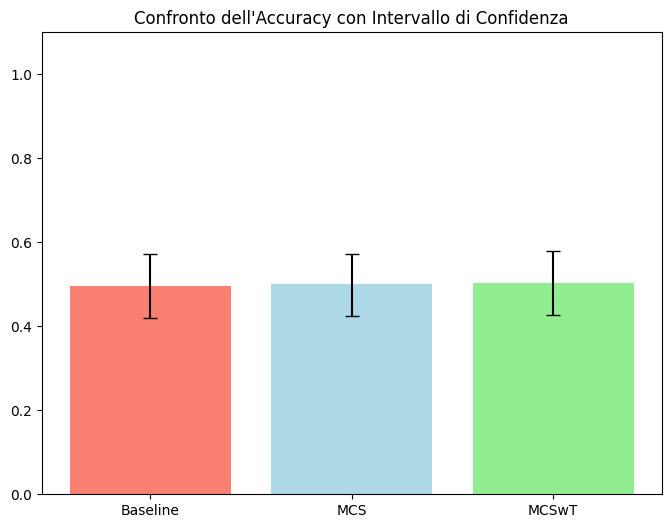

In [ ]:
x_axis_tags = ["Baseline", "MCS", "MCSwT"]
y_axis_tags = [baseline_accuracy_final, mcs_accuracy_final, mcswt_accuracy_final]

lower_errors = [
    baseline_accuracy_final - baseline_accuracy_confidence_interval[0],
    mcs_accuracy_final - mcs_accuracy_confidence_interval[0],
    mcswt_accuracy_final - mcswt_accuracy_confidence_interval[0]
]
upper_errors = [
    baseline_accuracy_confidence_interval[1] - baseline_accuracy_final,
    mcs_accuracy_confidence_interval[1] - mcs_accuracy_final,
    mcswt_accuracy_confidence_interval[1] - mcswt_accuracy_final
]
asymmetric_error = [lower_errors, upper_errors]

plt.figure(figsize=(8, 6))
plt.bar(x=x_axis_tags, height=y_axis_tags, yerr=asymmetric_error, capsize=5, color=['salmon', 'lightblue', 'lightgreen'])
plt.title("Confronto dell'Accuracy con Intervallo di Confidenza")
plt.ylim(0, 1.1)
plt.savefig('/content/third-milestone/LOOCV/final-results/accuracy_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

### Macro Averaged Precision
La precision misura quanti, tra i video che il modello ha classificato come appartenenti a una classe, appartengono effettivamente a quella classe.

La Macro Averaged Precision è la media aritmetica della precision della classe del conducente e della precision di quella del passeggero.

Il valore di Macro Averaged Precision finale mostrato in questo grafico è la media aritmetica dei valori di Macro Averaged Precision di tutti i 7 fold.

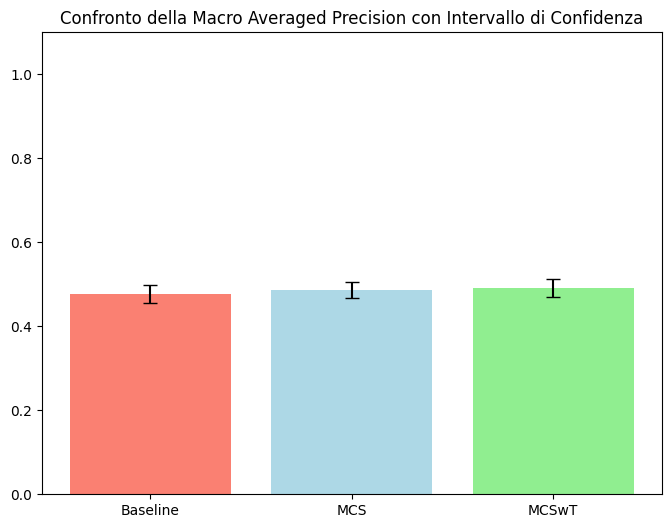

In [ ]:
x_axis_tags = ["Baseline", "MCS", "MCSwT"]
y_axis_tags = [baseline_MAP_final, mcs_MAP_final, mcswt_MAP_final]

lower_errors = [
    baseline_MAP_final - baseline_MAP_confidence_interval[0],
    mcs_MAP_final - mcs_MAP_confidence_interval[0],
    mcswt_MAP_final - mcswt_MAP_confidence_interval[0]
]
upper_errors = [
    baseline_MAP_confidence_interval[1] - baseline_MAP_final,
    mcs_MAP_confidence_interval[1] - mcs_MAP_final,
    mcswt_MAP_confidence_interval[1] - mcswt_MAP_final
]
asymmetric_error = [lower_errors, upper_errors]

plt.figure(figsize=(8, 6))
plt.bar(x=x_axis_tags, height=y_axis_tags, yerr=asymmetric_error, capsize=5, color=['salmon', 'lightblue', 'lightgreen'])
plt.title("Confronto della Macro Averaged Precision con Intervallo di Confidenza")
plt.ylim(0, 1.1)
plt.savefig('/content/third-milestone/LOOCV/final-results/precision_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

### Macro Averaged Recall
La recall misura la capacità del modello di trovare tutti i video reali appartenenti a una determinata classe.

La Macro Averaged Recall è la media aritmetica del Recall del conducente e del Recall del passeggero.

Il valore di Macro Averaged Recall finale mostrato in questo grafico è la media aritmetica dei valori di Macro Averaged Recall di tutti i 7 fold.

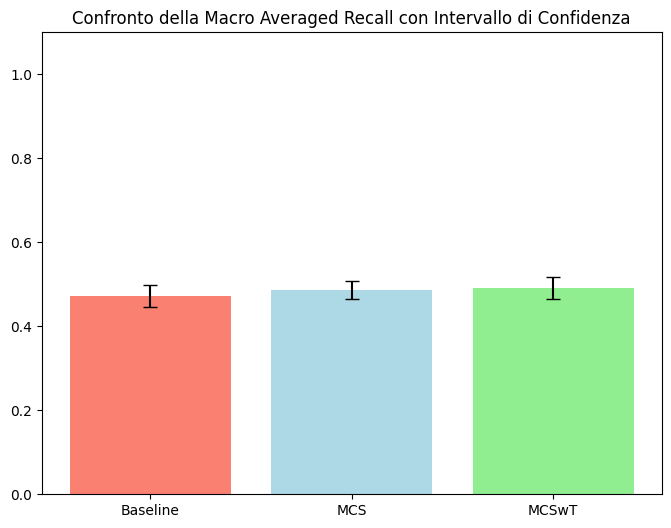

In [ ]:
x_axis_tags = ["Baseline", "MCS", "MCSwT"]
y_axis_tags = [baseline_MAR_final, mcs_MAR_final, mcswt_MAR_final]

lower_errors = [
    baseline_MAR_final - baseline_MAR_confidence_interval[0],
    mcs_MAR_final - mcs_MAR_confidence_interval[0],
    mcswt_MAR_final - mcswt_MAR_confidence_interval[0]
]
upper_errors = [
    baseline_MAR_confidence_interval[1] - baseline_MAR_final,
    mcs_MAR_confidence_interval[1] - mcs_MAR_final,
    mcswt_MAR_confidence_interval[1] - mcswt_MAR_final
]
asymmetric_error = [lower_errors, upper_errors]

plt.figure(figsize=(8, 6))
plt.bar(x=x_axis_tags, height=y_axis_tags, yerr=asymmetric_error, capsize=5, color=['salmon', 'lightblue', 'lightgreen'])
plt.title("Confronto della Macro Averaged Recall con Intervallo di Confidenza")
plt.ylim(0, 1.1)
plt.savefig('/content/third-milestone/LOOCV/final-results/recall_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

### Macro Averaged F-Measure
Metrica che integra Precision e Recall.

Il valore di Macro Averaged F-Measure finale mostrato in questo grafico è la media aritmetica dei valori di Macro Averaged F-Measure di tutti i 7 fold.

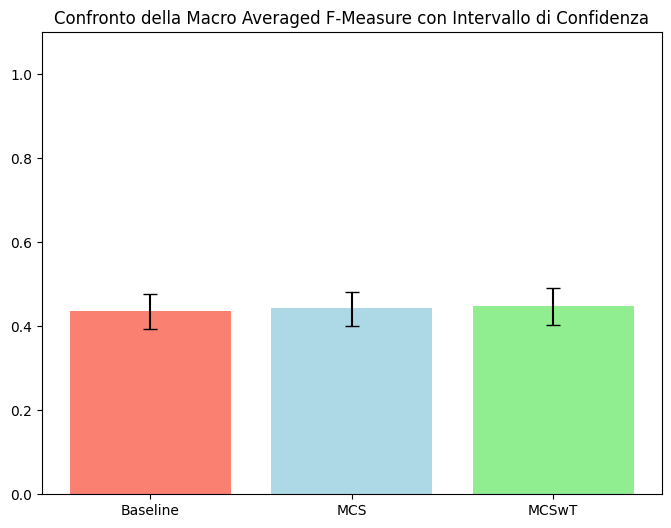

In [ ]:
x_axis_tags = ["Baseline", "MCS", "MCSwT"]
y_axis_tags = [baseline_offset_or_MAF := baseline_MAF_final, mcs_MAF_final, mcswt_MAF_final]

lower_errors = [
    baseline_MAF_final - baseline_MAF_confidence_interval[0],
    mcs_MAF_final - mcs_MAF_confidence_interval[0],
    mcswt_MAF_final - mcswt_MAF_confidence_interval[0]
]
upper_errors = [
    baseline_MAF_confidence_interval[1] - baseline_MAF_final,
    mcs_MAF_confidence_interval[1] - mcs_MAF_final,
    mcswt_MAF_confidence_interval[1] - mcswt_MAF_final
]
asymmetric_error = [lower_errors, upper_errors]

plt.figure(figsize=(8, 6))
plt.bar(x=x_axis_tags, height=y_axis_tags, yerr=asymmetric_error, capsize=5, color=['salmon', 'lightblue', 'lightgreen'])
plt.title("Confronto della Macro Averaged F-Measure con Intervallo di Confidenza")
plt.ylim(0, 1.1)
plt.savefig('/content/third-milestone/LOOCV/final-results/f_measure_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

## Delay medio
Il delay di uno specifico video è il numero di fotogrammi scansionati per giungere
al consenso dell'80% (ovvero, tra tutte le finestre scansionate fino al raggiungimento del delay, l'80% di esse concorda sulla decisione di maggioranza corrente, coerentemente con la formula del consenso interno).

Il delay di un fold è la media dei delay di tutti i video di test appartenenti al fold.

Il delay finale è semplicemente la media aritmetica dei delay medi dei fold.

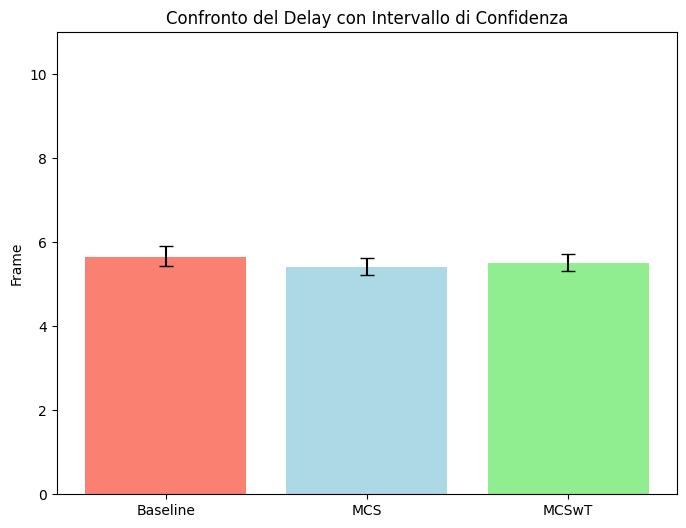

In [ ]:
x_axis_tags = ["Baseline", "MCS", "MCSwT"]
y_axis_tags = [baseline_delay_avg_final, mcs_delay_avg_final, mcswt_delay_avg_final]

lower_errors = [
    baseline_delay_avg_final - baseline_delay_avg_confidence_interval[0],
    mcs_delay_avg_final - mcs_delay_avg_confidence_interval[0],
    mcswt_delay_avg_final - mcswt_delay_avg_confidence_interval[0]
]
upper_errors = [
    baseline_delay_avg_confidence_interval[1] - baseline_delay_avg_final,
    mcs_delay_avg_confidence_interval[1] - mcs_delay_avg_final,
    mcswt_delay_avg_confidence_interval[1] - mcswt_delay_avg_final
]
asymmetric_error = [lower_errors, upper_errors]

plt.figure(figsize=(8, 6))
plt.bar(x=x_axis_tags, height=y_axis_tags, yerr=asymmetric_error, capsize=5, color=['salmon', 'lightblue', 'lightgreen'])
plt.title("Confronto del Delay con Intervallo di Confidenza")
plt.ylabel("Frame")
plt.ylim(0, 11)
plt.savefig('/content/third-milestone/LOOCV/final-results/delay_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

## 10 - Salvataggio su Google Drive ed esportazione dei risultati (KOICV)


In [2]:
from pathlib import Path
import json
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive

MILESTONE = 'third-milestone'
PROTOCOL = 'KOICV'

def export_milestone(milestone, protocol, drive_root, local_root, live_variables):
    drive_root = Path(drive_root)
    local_root = Path(local_root)
    target = drive_root / 'tesi-finale' / milestone
    fold_names = [f'fold{i}' for i in range(1, 8)]
    heuristics_export = [('baseline', 'Baseline', 'baseline'), ('MCS', 'MCS', 'mcs'), ('MCSwT', 'MCSwT', 'mcswt')]
    specs = [('Accuracy', 'accuracy', 'accuracy_comparison.png'),
             ('MAP', 'MAP', 'precision_comparison.png'),
             ('MAR', 'MAR', 'recall_comparison.png'),
             ('MAF', 'MAF', 'f_measure_comparison.png'),
             ('Delay Average', 'delay_avg', 'delay_comparison.png')]
    thresholds = [0.4, 0.75, 0.8, 0.85, 0.9, 0.95, 0.99]
    classes = ['driver-seat-belt', 'driver-sun-visor', 'driver-window', 'passenger-grab-handle',
               'passenger-seat-belt', 'passenger-sun-visor', 'passenger-window']
    colors = ['salmon', 'lightblue', 'lightgreen']

    candidates = [(local_root, local_root / 'LOOCV'),
                  (target, target / protocol), (target, target / 'LOOCV'),
                  (drive_root / 'tesi' / milestone, drive_root / 'tesi' / milestone / 'LOOCV'),
                  (drive_root / 'tesi' / milestone, drive_root / 'tesi' / milestone / protocol)]
    def complete(root, experiment):
        return (root / 'dataset-originale').is_dir() and all(
            (experiment / 'results' / fold / name).is_file()
            for fold in fold_names for name in ('predictions.json', 'metrics.json')
        ) and all((experiment / 'configurations' / fold / name).is_file()
                  for fold in fold_names for name in ('train.txt', 'val.txt'))
    source = next(((root, exp) for root, exp in candidates if complete(root, exp)), None)
    if source is None:
        raise FileNotFoundError('Archivio completo non trovato. Servono dataset-originale, configurations e predictions.json/metrics.json dei sette fold. Percorsi controllati: ' + ', '.join(str(p) for _, p in candidates))
    source_root, experiment = source
    print(f'Archivio utilizzato: {experiment}')
    dataset = source_root / 'dataset-originale'
    predictions_by_fold = {f: json.loads((experiment / 'results' / f / 'predictions.json').read_text(encoding='utf-8')) for f in fold_names}
    metrics_by_fold = {f: json.loads((experiment / 'results' / f / 'metrics.json').read_text(encoding='utf-8')) for f in fold_names}
    all_images = {p.relative_to(dataset).as_posix() for p in dataset.glob('set*/*/images/*') if p.is_file() and p.suffix.lower() in ('.jpg', '.jpeg', '.png')}
    if not all_images:
        raise ValueError('Nessuna immagine trovata nel dataset originale.')
    def read_split(path):
        items = [Path(line.strip()).parts[-4:] for line in path.read_text(encoding='utf-8').splitlines() if line.strip()]
        rel = [Path(*parts).as_posix() for parts in items]
        if len(rel) != len(set(rel)) or not set(rel) <= all_images:
            raise ValueError(f'Percorsi duplicati o non riconosciuti in {path}')
        return set(rel)
    splits_by_fold = {}
    for fold in fold_names:
        config = experiment / 'configurations' / fold
        train, val = read_split(config / 'train.txt'), read_split(config / 'val.txt')
        if train & val:
            raise ValueError(f'{fold}: sovrapposizione tra training e validation.')
        test = all_images - train - val
        video_ids = lambda images: {str(Path(p).parent.parent) for p in images}
        if video_ids(train) & video_ids(val) or video_ids(train) & video_ids(test) or video_ids(val) & video_ids(test):
            raise ValueError(f'{fold}: un video compare in piu' + ' insiemi.')
        if len(video_ids(test)) != len(predictions_by_fold[fold]):
            raise ValueError(f'{fold}: numero di video di test diverso dal numero di predizioni.')
        splits_by_fold[fold] = {'Train': train, 'Val': val, 'Test': test}

    training_dir = target / 'training'
    plots_dir = target / 'test' / 'plots'
    results_dir = target / 'test' / 'results'
    for directory in (training_dir, plots_dir, results_dir):
        directory.mkdir(parents=True, exist_ok=True)

    if source_root == local_root:
        shutil.copytree(dataset, target / 'dataset-originale', dirs_exist_ok=True)
        shutil.copytree(experiment, target / protocol, dirs_exist_ok=True)
    (results_dir / 'source_archive.txt').write_text(str(target / protocol if source_root == local_root else experiment) + '\n', encoding='utf-8')

    def save_figure(fig, path):
        fig.tight_layout()
        fig.savefig(path, dpi=300, bbox_inches='tight')
        plt.close(fig)

    def save_bar(df, index_col, cols, title, ylabel, path, figsize=(12, 6), rotation=0):
        fig, ax = plt.subplots(figsize=figsize)
        df.set_index(index_col)[cols].plot(kind='bar', ax=ax)
        ax.set_title(title)
        ax.set_ylabel(ylabel)
        ax.tick_params(axis='x', labelrotation=rotation)
        if rotation:
            for label in ax.get_xticklabels():
                label.set_ha('right')
        ax.grid(axis='y', linestyle='--', alpha=0.7)
        save_figure(fig, path)

    image_info = {}
    video_classes = {}
    for relative in sorted(all_images):
        p = dataset / relative
        video_dir = p.parent.parent
        if video_dir not in video_classes:
            markers = list(video_dir.glob('*.class'))
            if len(markers) != 1 or markers[0].stem not in ('driver', 'passenger'):
                raise ValueError(f'Classe reale non valida: {p}')
            video_classes[video_dir] = markers[0].stem
        counts = [0] * len(classes)
        label_path = p.parent.parent / 'labels' / (p.stem + '.txt')
        for line in label_path.read_text(encoding='utf-8').splitlines():
            if line.strip():
                class_id = int(line.split()[0])
                if not 0 <= class_id < len(classes):
                    raise ValueError(f'ID classe non valido in {label_path}')
                counts[class_id] += 1
        image_info[relative] = (video_classes[video_dir], counts)

    dataset_rows = []
    for participant in sorted({Path(p).parts[0] for p in all_images}):
        imgs = [p for p in all_images if Path(p).parts[0] == participant]
        dataset_rows.append({'Partecipante': participant, 'Video': len(video_ids(imgs)), 'Fotogrammi': len(imgs),
                             'Driver_Frames': sum(image_info[p][0] == 'driver' for p in imgs),
                             'Passenger_Frames': sum(image_info[p][0] == 'passenger' for p in imgs)})
    df_participants = pd.DataFrame(dataset_rows)
    df_participants.to_csv(training_dir / 'distribuzione_partecipanti.csv', index=False)
    save_bar(df_participants, 'Partecipante', ['Driver_Frames', 'Passenger_Frames'], 'Distribuzione dei fotogrammi per partecipante', 'Numero di fotogrammi', training_dir / 'distribuzione_partecipanti.png')

    def summary(values, intervals):
        table = {'Metric': [name for name, _, _ in specs]}
        for _, display_name, prefix in heuristics_export:
            keys = [f'{prefix}_{suffix}' for _, suffix, _ in specs]
            table[f'{display_name}_Value'] = [values[k] for k in keys]
            table[f'{display_name}_CI_Lower'] = [intervals[k][0] for k in keys]
            table[f'{display_name}_CI_Upper'] = [intervals[k][1] for k in keys]
        return pd.DataFrame(table)

    def metric_chart(row, filename, title):
        names = [h[1] for h in heuristics_export]
        vals = np.array([row[f'{h}_Value'] for h in names])
        lower = np.array([row[f'{h}_CI_Lower'] for h in names])
        upper = np.array([row[f'{h}_CI_Upper'] for h in names])
        fig, ax = plt.subplots(figsize=(8, 6))
        ax.bar(names, vals, yerr=np.maximum(0, [vals - lower, upper - vals]), capsize=5, color=colors)
        ax.set_title(title + ' - I.C. al 95%')
        ax.set_ylim(0, 11 if row['Metric'] == 'Delay Average' else 1.1)
        if row['Metric'] == 'Delay Average':
            ax.set_ylabel('Frame')
        save_figure(fig, filename)

    fold_tables, all_video_rows, all_threshold_rows, all_frame_rows = [], [], [], []
    micro_tables, macro_tables = [], []
    all_confusion_rows = []
    for fold in fold_names:
        train_fold = training_dir / fold
        result_fold = results_dir / fold
        plot_fold = plots_dir / fold
        for directory in (train_fold, result_fold, plot_fold):
            directory.mkdir(parents=True, exist_ok=True)
        split = splits_by_fold[fold]
        micro = {'Classe': classes}
        macro = []
        for name, images in split.items():
            micro[f'{name}_Count'] = np.sum([image_info[p][1] for p in images], axis=0).tolist()
            macro.append({'Split': name, 'Driver_Frames': sum(image_info[p][0] == 'driver' for p in images),
                          'Passenger_Frames': sum(image_info[p][0] == 'passenger' for p in images),
                          'Unclassified_Frames': 0, 'Video': len(video_ids(images))})
        df_micro, df_macro = pd.DataFrame(micro), pd.DataFrame(macro)
        df_micro.to_csv(train_fold / 'sbilanciamento_micro_classi.csv', index=False)
        df_macro.to_csv(train_fold / 'sbilanciamento_macro_classi.csv', index=False)
        save_bar(df_micro, 'Classe', ['Train_Count', 'Val_Count', 'Test_Count'], f'{fold} - Distribuzione delle micro-classi', 'Numero di istanze (Bounding Boxes)', train_fold / 'sbilanciamento_micro_classi.png', rotation=45)
        save_bar(df_macro, 'Split', ['Driver_Frames', 'Passenger_Frames'], f'{fold} - Distribuzione delle macro-classi', 'Numero di fotogrammi', train_fold / 'sbilanciamento_macro_classi.png', figsize=(10, 5))
        micro_tables.append(df_micro.assign(Fold=fold))
        macro_tables.append(df_macro.assign(Fold=fold))

        model_dir = experiment / 'models' / fold
        for src_name, dst_name in [('results.png', 'results_training_curves.png'), ('results.csv', 'metrica_training_risultati.csv'),
                                   ('confusion_matrix.png', 'confusion_matrix_train.png'), ('confusion_matrix_normalized.png', 'confusion_matrix_normalized.png')]:
            src = model_dir / src_name
            if src.is_file():
                shutil.copy2(src, train_fold / dst_name)
            else:
                print(f'[ATTENZIONE] {fold}: {src_name} non disponibile nell\'archivio.')

        for name in ('predictions.json', 'metrics.json'):
            shutil.copy2(experiment / 'results' / fold / name, result_fold / name)
        for name in ('train.txt', 'val.txt', 'data.yaml'):
            src = experiment / 'configurations' / fold / name
            if src.is_file():
                shutil.copy2(src, train_fold / name)
        m = metrics_by_fold[fold]
        intervals = {f'{prefix}_{suffix}': m[f'{prefix}_{"delay" if suffix == "delay_avg" else suffix}_confidence_interval']
                     for _, _, prefix in heuristics_export for _, suffix, _ in specs}
        df_fold = summary(m, intervals)
        df_fold.to_csv(result_fold / 'metrics_summary.csv', index=False)
        fold_tables.append(df_fold.assign(Fold=fold))
        for (_, _, filename), (_, row) in zip(specs, df_fold.iterrows()):
            metric_chart(row, plot_fold / filename, f'{fold} - {row["Metric"]}')

        video_rows, threshold_rows, frame_rows = [], [], []
        for i, pred in enumerate(predictions_by_fold[fold]):
            real, decisions, frame_classes, timings = pred[:4]
            for h, display_name, _ in heuristics_export:
                video_rows.append({'Fold': fold, 'Video_Index': i, 'Real_Class': real, 'Heuristic': display_name,
                                   'Prediction': decisions[h], 'Delay_Frames': timings['2'][h][1]})
                for idx, threshold in enumerate(thresholds):
                    consensus, delay = timings[str(idx)][h]
                    threshold_rows.append({'Fold': fold, 'Video_Index': i, 'Heuristic': display_name, 'Threshold': threshold,
                                           'Consensus': consensus, 'Delay_Frames': delay})
                for frame, label in enumerate(frame_classes[h], start=1):
                    frame_rows.append({'Fold': fold, 'Video_Index': i, 'Frame': frame, 'Real_Class': real,
                                       'Heuristic': display_name, 'Prediction': label})
        df_video, df_threshold, df_frames = map(pd.DataFrame, (video_rows, threshold_rows, frame_rows))
        df_video.to_csv(result_fold / 'video_predictions.csv', index=False)
        df_threshold.to_csv(result_fold / 'intermediate_results.csv', index=False)
        df_frames.to_csv(result_fold / 'frame_predictions.csv', index=False)
        all_video_rows.extend(video_rows)
        all_threshold_rows.extend(threshold_rows)
        all_frame_rows.extend(frame_rows)
        for _, display_name, _ in heuristics_export:
            subset = df_video[df_video['Heuristic'] == display_name]
            matrix = pd.crosstab(subset['Real_Class'], subset['Prediction']).reindex(index=['driver','passenger'], columns=['driver','passenger','none'], fill_value=0)
            matrix.to_csv(result_fold / f'confusion_matrix_{display_name}.csv')
            fig, ax = plt.subplots(figsize=(6, 4))
            im = ax.imshow(matrix.values, cmap='Blues')
            for r in range(2):
                for c in range(3):
                    ax.text(c, r, str(matrix.iloc[r, c]), ha='center', va='center', color='white' if matrix.iloc[r,c] > matrix.values.max()/2 else 'black')
                    all_confusion_rows.append({'Fold': fold, 'Heuristic': display_name, 'Real_Class': matrix.index[r], 'Prediction': matrix.columns[c], 'Count': matrix.iloc[r,c]})
            ax.set_xticks(range(3), matrix.columns)
            ax.set_yticks(range(2), matrix.index)
            ax.set_xlabel('Classe predetta')
            ax.set_ylabel('Classe reale')
            ax.set_title(f'{fold} - {display_name}')
            fig.colorbar(im, ax=ax)
            save_figure(fig, plot_fold / f'confusion_matrix_{display_name}.png')
        print(f'[OK] {fold}: {len(predictions_by_fold[fold])} video, risultati e grafici esportati.')

    pd.concat(micro_tables, ignore_index=True).to_csv(training_dir / 'sbilanciamento_micro_classi_per_fold.csv', index=False)
    pd.concat(macro_tables, ignore_index=True).to_csv(training_dir / 'sbilanciamento_macro_classi_per_fold.csv', index=False)
    df_folds = pd.concat(fold_tables, ignore_index=True)
    df_folds[['Fold'] + [c for c in df_folds.columns if c != 'Fold']].to_csv(results_dir / 'fold_metrics_summary.csv', index=False)
    pd.DataFrame(all_video_rows).to_csv(results_dir / 'video_predictions.csv', index=False)
    pd.DataFrame(all_frame_rows).to_csv(results_dir / 'frame_predictions.csv', index=False)
    df_all_thresholds = pd.DataFrame(all_threshold_rows)
    df_all_thresholds.to_csv(results_dir / 'intermediate_results.csv', index=False)
    pd.DataFrame(all_confusion_rows).to_csv(results_dir / 'confusion_matrices_per_fold.csv', index=False)

    threshold_by_fold = df_all_thresholds.groupby(['Fold', 'Heuristic', 'Threshold'], as_index=False)['Delay_Frames'].mean()
    threshold_by_fold.to_csv(results_dir / 'intermediate_delay_over_thresholds_per_fold.csv', index=False)
    df_delay = threshold_by_fold.groupby(['Heuristic', 'Threshold'], as_index=False)['Delay_Frames'].mean()
    df_delay.to_csv(results_dir / 'intermediate_delay_over_thresholds.csv', index=False)
    fig, ax = plt.subplots(figsize=(10, 6))
    for _, display_name, _ in heuristics_export:
        data = df_delay[df_delay['Heuristic'] == display_name]
        ax.plot(data['Threshold'], data['Delay_Frames'], marker='s', label=display_name)
    ax.set_title('Delay medio al variare della soglia di confidenza (media dei sette fold)')
    ax.set_xlabel('Soglia di confidenza')
    ax.set_ylabel('Delay medio (frame)')
    ax.grid(True)
    ax.legend()
    save_figure(fig, plots_dir / 'intermediate_delay_over_thresholds.png')

    for metric, _, filename in specs:
        data = df_folds[df_folds['Metric'] == metric]
        fig, ax = plt.subplots(figsize=(12, 6))
        x = np.arange(len(fold_names))
        for j, (_, display_name, _) in enumerate(heuristics_export):
            vals = data[f'{display_name}_Value'].to_numpy()
            lo = data[f'{display_name}_CI_Lower'].to_numpy()
            hi = data[f'{display_name}_CI_Upper'].to_numpy()
            ax.bar(x + (j-1)*0.25, vals, width=0.25, yerr=np.maximum(0,[vals-lo, hi-vals]), capsize=3, color=colors[j], label=display_name)
        ax.set_xticks(x, fold_names)
        ax.set_title(f'{metric} per fold - I.C. al 95%')
        ax.set_ylim(0, 11 if metric == 'Delay Average' else 1.1)
        ax.legend()
        save_figure(fig, plots_dir / f'per_fold_{filename}')

    final_values, final_intervals = {}, {}
    rng = np.random.RandomState(42)
    use_live = source_root == local_root and all(
        f'{prefix}_{suffix}_final' in live_variables and f'{prefix}_{suffix}_confidence_interval' in live_variables
        and np.isclose(live_variables[f'{prefix}_{suffix}_final'], np.mean([metrics_by_fold[f][f'{prefix}_{suffix}'] for f in fold_names]))
        for _, _, prefix in heuristics_export for _, suffix, _ in specs)
    for _, _, prefix in heuristics_export:
        for _, suffix, _ in specs:
            key = f'{prefix}_{suffix}'
            values = np.array([metrics_by_fold[f][key] for f in fold_names], dtype=float)
            if use_live:
                final_values[key] = float(live_variables[f'{key}_final'])
                final_intervals[key] = live_variables[f'{key}_confidence_interval']
            else:
                final_values[key] = float(values.mean())
                sampled_means = rng.choice(values, size=(10000, len(values)), replace=True).mean(axis=1)
                final_intervals[key] = np.percentile(sampled_means, [2.5, 97.5])
    df_final = summary(final_values, final_intervals)
    df_final.to_csv(results_dir / 'final_metrics_summary.csv', index=False)
    for (_, _, filename), (_, row) in zip(specs, df_final.iterrows()):
        metric_chart(row, plots_dir / filename, f'{row["Metric"]} - media dei sette fold')
    (results_dir / 'note_intervalli.txt').write_text(
        ('Intervalli finali recuperati dalle variabili in memoria.\n' if use_live else 'Intervalli finali ricalcolati dai sette metrics.json: bootstrap percentile, 10000 ricampionamenti, seed 42. Possono differire leggermente dagli intervalli storici.\n')
        + 'Medie aritmetiche dei sette fold. Metriche di classificazione in frazione; Delay in fotogrammi. Intervalli bootstrap approssimati: i fold non sono indipendenti.\n'
        + 'Le matrici di confusione esportate mostrano le predizioni none effettive, mentre le metriche mantengono la convenzione penalizzante originale.\n', encoding='utf-8')
    print(f'\n[OK] Risultati finali e intermedi salvati in {target}')
    display(df_final)
    return df_final


drive.mount('/content/gdrive')
final_metrics_export = export_milestone(MILESTONE, PROTOCOL, Path('/content/gdrive/MyDrive'), Path('/content') / MILESTONE, globals())
drive.flush_and_unmount()

Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).
Archivio utilizzato: /content/gdrive/MyDrive/tesi/third-milestone/LOOCV
[OK] fold1: 160 video, risultati e grafici esportati.
[OK] fold2: 160 video, risultati e grafici esportati.
[OK] fold3: 176 video, risultati e grafici esportati.
[OK] fold4: 160 video, risultati e grafici esportati.
[OK] fold5: 160 video, risultati e grafici esportati.
[OK] fold6: 176 video, risultati e grafici esportati.
[OK] fold7: 160 video, risultati e grafici esportati.

[OK] Risultati finali e intermedi salvati in /content/gdrive/MyDrive/tesi-finale/third-milestone


,Metric,Baseline_Value,Baseline_CI_Lower,Baseline_CI_Upper,MCS_Value,MCS_CI_Lower,MCS_CI_Upper,MCSwT_Value,MCSwT_CI_Lower,MCSwT_CI_Upper
0,Accuracy,0.495942,0.418750,0.576380,0.500162,0.423131,0.572971,0.502760,0.425649,0.579140
1,MAP,0.476646,0.453777,0.498510,0.485715,0.467819,0.504430,0.490939,0.468782,0.514159
2,MAR,0.472403,0.445831,0.497240,0.485714,0.464610,0.507143,0.490909,0.463907,0.517857
3,MAF,0.436176,0.394709,0.477134,0.444043,0.400905,0.481063,0.448941,0.405349,0.490563
4,Delay Average,5.661201,5.438799,5.900000,5.400649,5.213149,5.633929,5.496266,5.324188,5.709416
